# VAB real departamental y recuperación posterior a 2020

Este cuaderno consulta las mismas estimaciones que el artículo y la presentación. Para regenerarlas ejecuta `python src/generar_analisis_completo.py`; no hay una segunda implementación de M1–M6 en el cuaderno.

El dato observado es VAB real a precios constantes de 2007. Las tasas y los niveles usan ventanas distintas. Las interacciones comparan cambios entre periodos y grupos; no identifican una pérdida causal exclusiva del COVID. Los errores se agrupan por departamento y la inferencia está limitada por los pocos departamentos del perfil enclave.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "analisis.toml").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Ejecuta el cuaderno dentro del repositorio")
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
manifest = json.loads((DATA / "resultados.json").read_text(encoding="utf-8"))
display(pd.Series(manifest["diagnostico"]))


gap_regla_1ee_k                                                       1
levene                {'stat': 3.598357641122534, 'p': 0.01372310476...
fligner               {'stat': 16.54272423668461, 'p': 0.00087748694...
ratio_desviaciones                                              4.32951
ceros                                                                 0
n_sectores                                                           11
n_departamentos                                                      24
n_base                                                              428
n_tasas                                                             384
n_niveles                                                           168
dtype: object

In [2]:
panel = pd.read_excel(DATA / "panel_econometrico_final.xlsx")
models = pd.read_excel(DATA / "resumen_modelos_econometricos.xlsx")
display(panel.groupby("anio").departamento.nunique().rename("departamentos"))
display(models.groupby("Modelo")[["N_obs", "R2_within"]].first())
display(models)
display(pd.read_excel(DATA / "volatilidad.xlsx", index_col=0))
post = models[models.Parametro.str.startswith("POST_21_23:")]
display(post[["Modelo", "Parametro", "Coeficiente", "Error_Estandar", "P_valor", "IC_inferior", "IC_superior"]])

anio
2008    24
2009    24
2010    24
2011    24
2012    24
2013    24
2014    24
2015    24
2016    24
2017    24
2018    24
2019    24
2020    24
2021    24
2022    24
2023    24
2024    22
2025    22
Name: departamentos, dtype: int64

,N_obs,R2_within
Modelo,,
M1,384,0.145041
M2,384,0.140522
M3,384,0.142336
M4,383,0.277162
M5,168,0.355429
M6,168,0.345055


,Modelo,Dependiente,Parametro,Coeficiente,Error_Estandar,T_stat,P_valor,IC_inferior,IC_superior,R2_within,N_obs,Poolability_F,Poolability_p
0,M1,crecimiento_vab,Intercept,4.577951,0.218980,20.905751,0.000000e+00,4.147277,5.008626,0.145041,384,0.911815,0.582798
1,M1,crecimiento_vab,COVID,-12.405556,1.899211,-6.531952,2.274263e-10,-16.140784,-8.670328,0.145041,384,0.911815,0.582798
2,M1,crecimiento_vab,POST_21_23,-0.608889,0.639909,-0.951524,3.419915e-01,-1.867415,0.649638,0.145041,384,0.911815,0.582798
3,M1,crecimiento_vab,COVID:Nombre_Cluster_K4[T.Servicios/Manufactura],-2.603460,2.123644,-1.225940,2.210408e-01,-6.780085,1.573166,0.145041,384,0.911815,0.582798
4,M1,crecimiento_vab,COVID:Nombre_Cluster_K4[T.Minero/Diversificado],-1.218611,3.781097,-0.322290,7.474240e-01,-8.654993,6.217771,0.145041,384,0.911815,0.582798
5,M1,crecimiento_vab,COVID:Nombre_Cluster_K4[T.Minero/Enclave],-5.933056,4.316926,-1.374371,1.702010e-01,-14.423267,2.557155,0.145041,384,0.911815,0.582798
6,M1,crecimiento_vab,POST_21_23:Nombre_Cluster_K4[T.Servicios/Manuf...,1.105934,0.970035,1.140097,2.550211e-01,-0.801860,3.013728,0.145041,384,0.911815,0.582798
7,M1,crecimiento_vab,POST_21_23:Nombre_Cluster_K4[T.Minero/Diversif...,2.457103,2.178742,1.127763,2.601883e-01,-1.827885,6.742091,0.145041,384,0.911815,0.582798
8,M1,crecimiento_vab,POST_21_23:Nombre_Cluster_K4[T.Minero/Enclave],-2.109722,5.432084,-0.388382,6.979683e-01,-12.793143,8.573699,0.145041,384,0.911815,0.582798
9,M2,crecimiento_vab,Intercept,4.577951,0.228796,20.008848,0.000000e+00,4.127989,5.027914,0.140522,384,0.865136,0.646302


,std,count,std_sin_exclusion
Nombre_Cluster_K4,,,
Diversificado/Agro,4.909992,48,4.909992
Servicios/Manufactura,5.904903,176,5.904903
Minero/Diversificado,8.542247,112,8.542247
Minero/Enclave,21.257858,48,6.984025


,Modelo,Parametro,Coeficiente,Error_Estandar,P_valor,IC_inferior,IC_superior
6,M1,POST_21_23:Nombre_Cluster_K4[T.Servicios/Manuf...,1.105934,0.970035,0.255021,-0.801860,3.013728
7,M1,POST_21_23:Nombre_Cluster_K4[T.Minero/Diversif...,2.457103,2.178742,0.260188,-1.827885,6.742091
8,M1,POST_21_23:Nombre_Cluster_K4[T.Minero/Enclave],-2.109722,5.432084,0.697968,-12.793143,8.573699
13,M2,POST_21_23:Macro[T.Minero],0.218107,2.344355,0.925928,-4.392419,4.828634
18,M3,POST_21_23:Mineria_z,-0.153120,1.404446,0.913244,-2.915175,2.608934
25,M4,POST_21_23:Nombre_Cluster_K4[T.Servicios/Manuf...,1.105934,0.970066,0.255038,-0.801938,3.013807
26,M4,POST_21_23:Nombre_Cluster_K4[T.Minero/Diversif...,2.457103,2.178810,0.260205,-1.828061,6.742268
27,M4,POST_21_23:Nombre_Cluster_K4[T.Minero/Enclave],1.701893,2.784594,0.541475,-3.774696,7.178481
34,M5,POST_21_23:Nombre_Cluster_K4[T.Servicios/Manuf...,-1.448180,2.251450,0.521164,-5.900560,3.004200
35,M5,POST_21_23:Nombre_Cluster_K4[T.Minero/Diversif...,-3.255389,5.708542,0.569438,-14.544378,8.033600


## Figuras finales

Las notas de interpretación, referencias y limitaciones se desarrollan en el artículo CCDE.

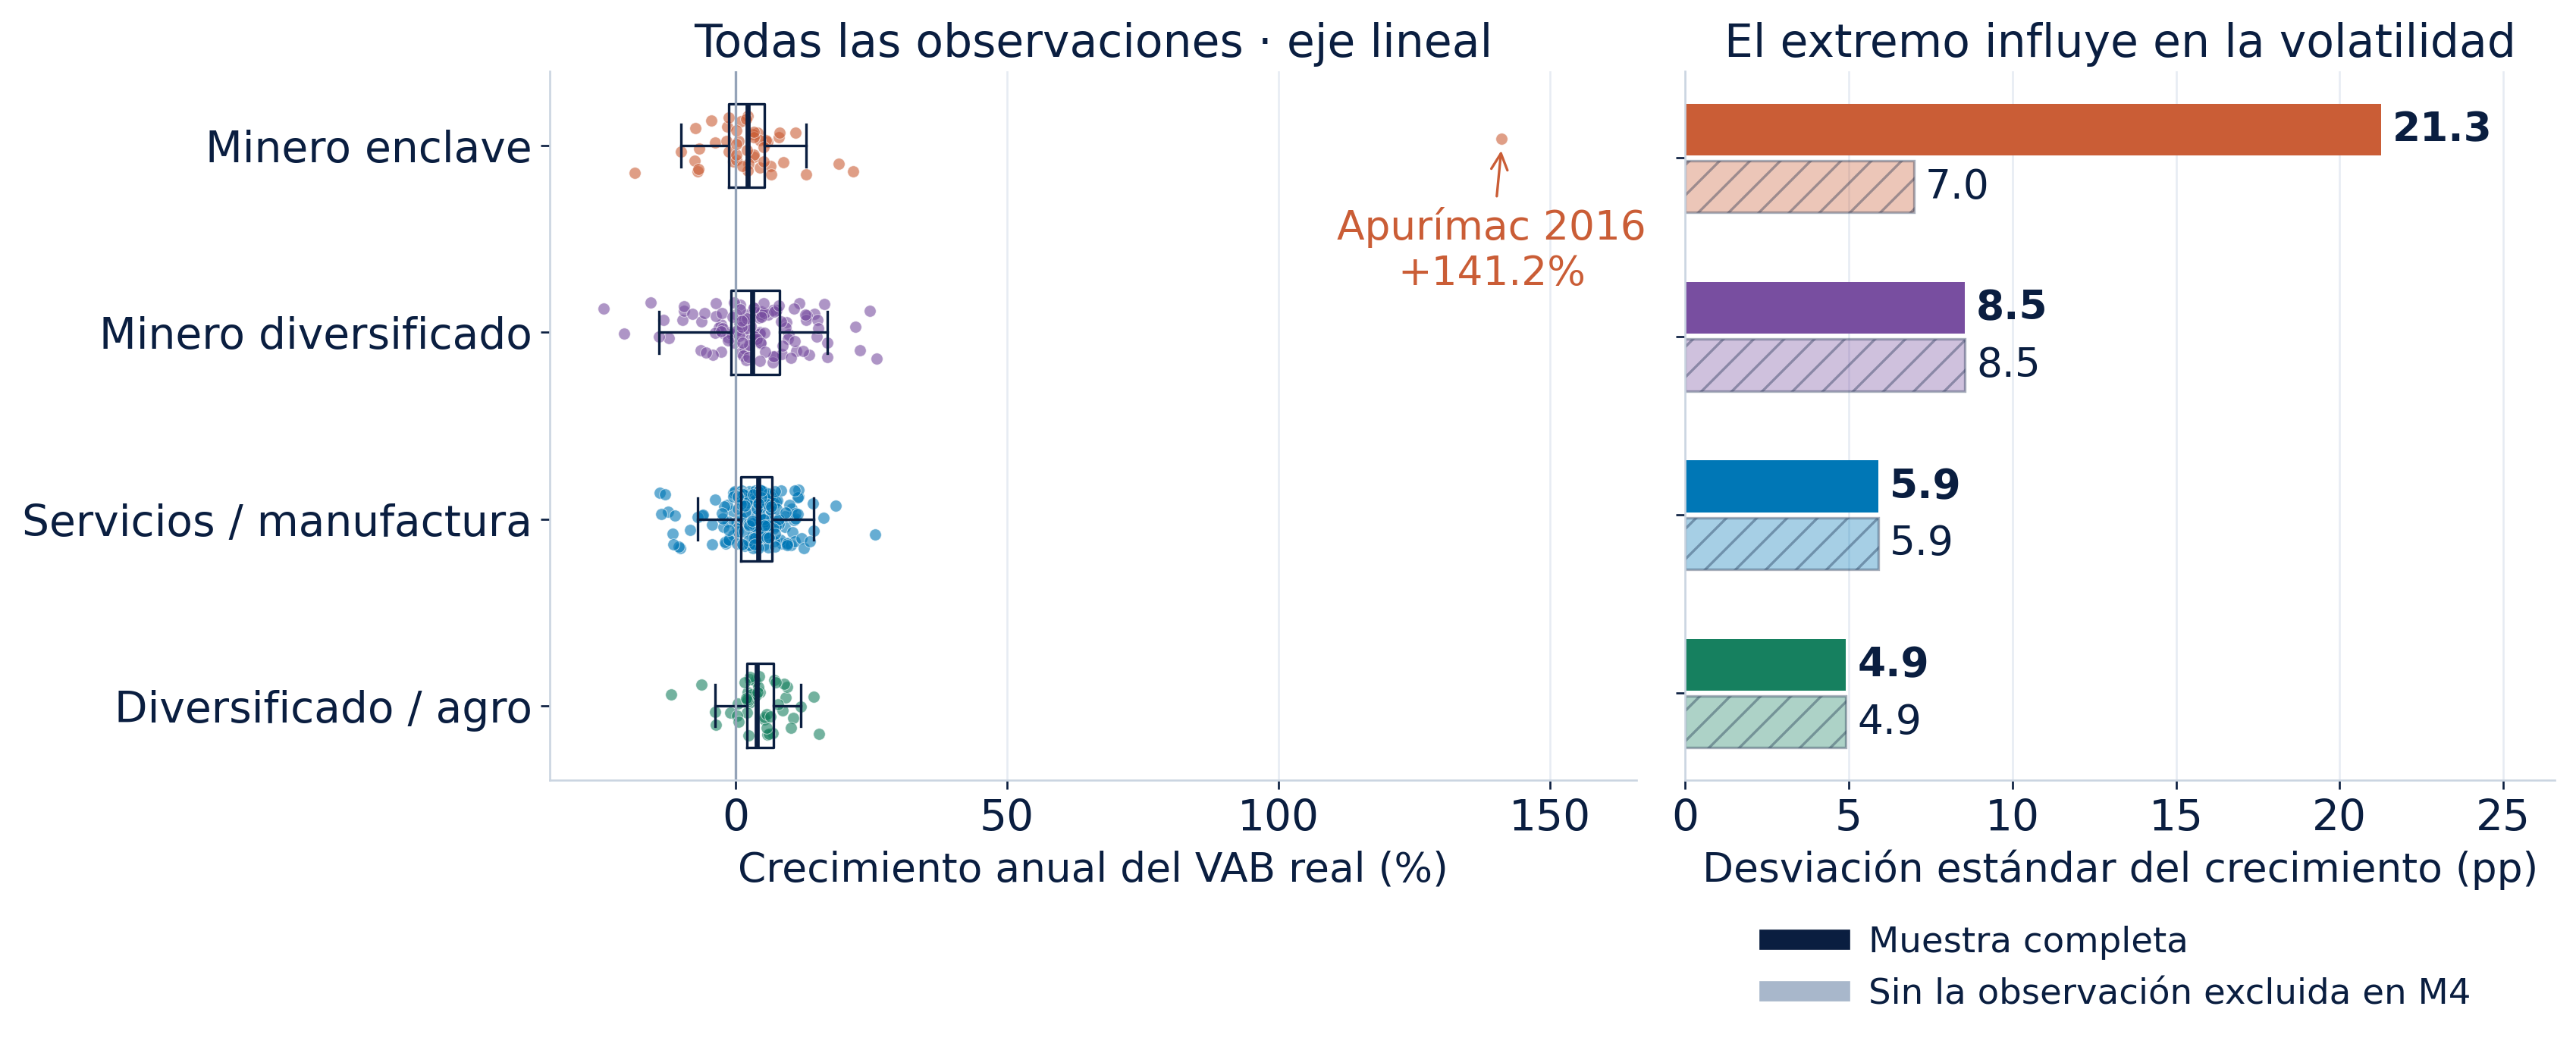

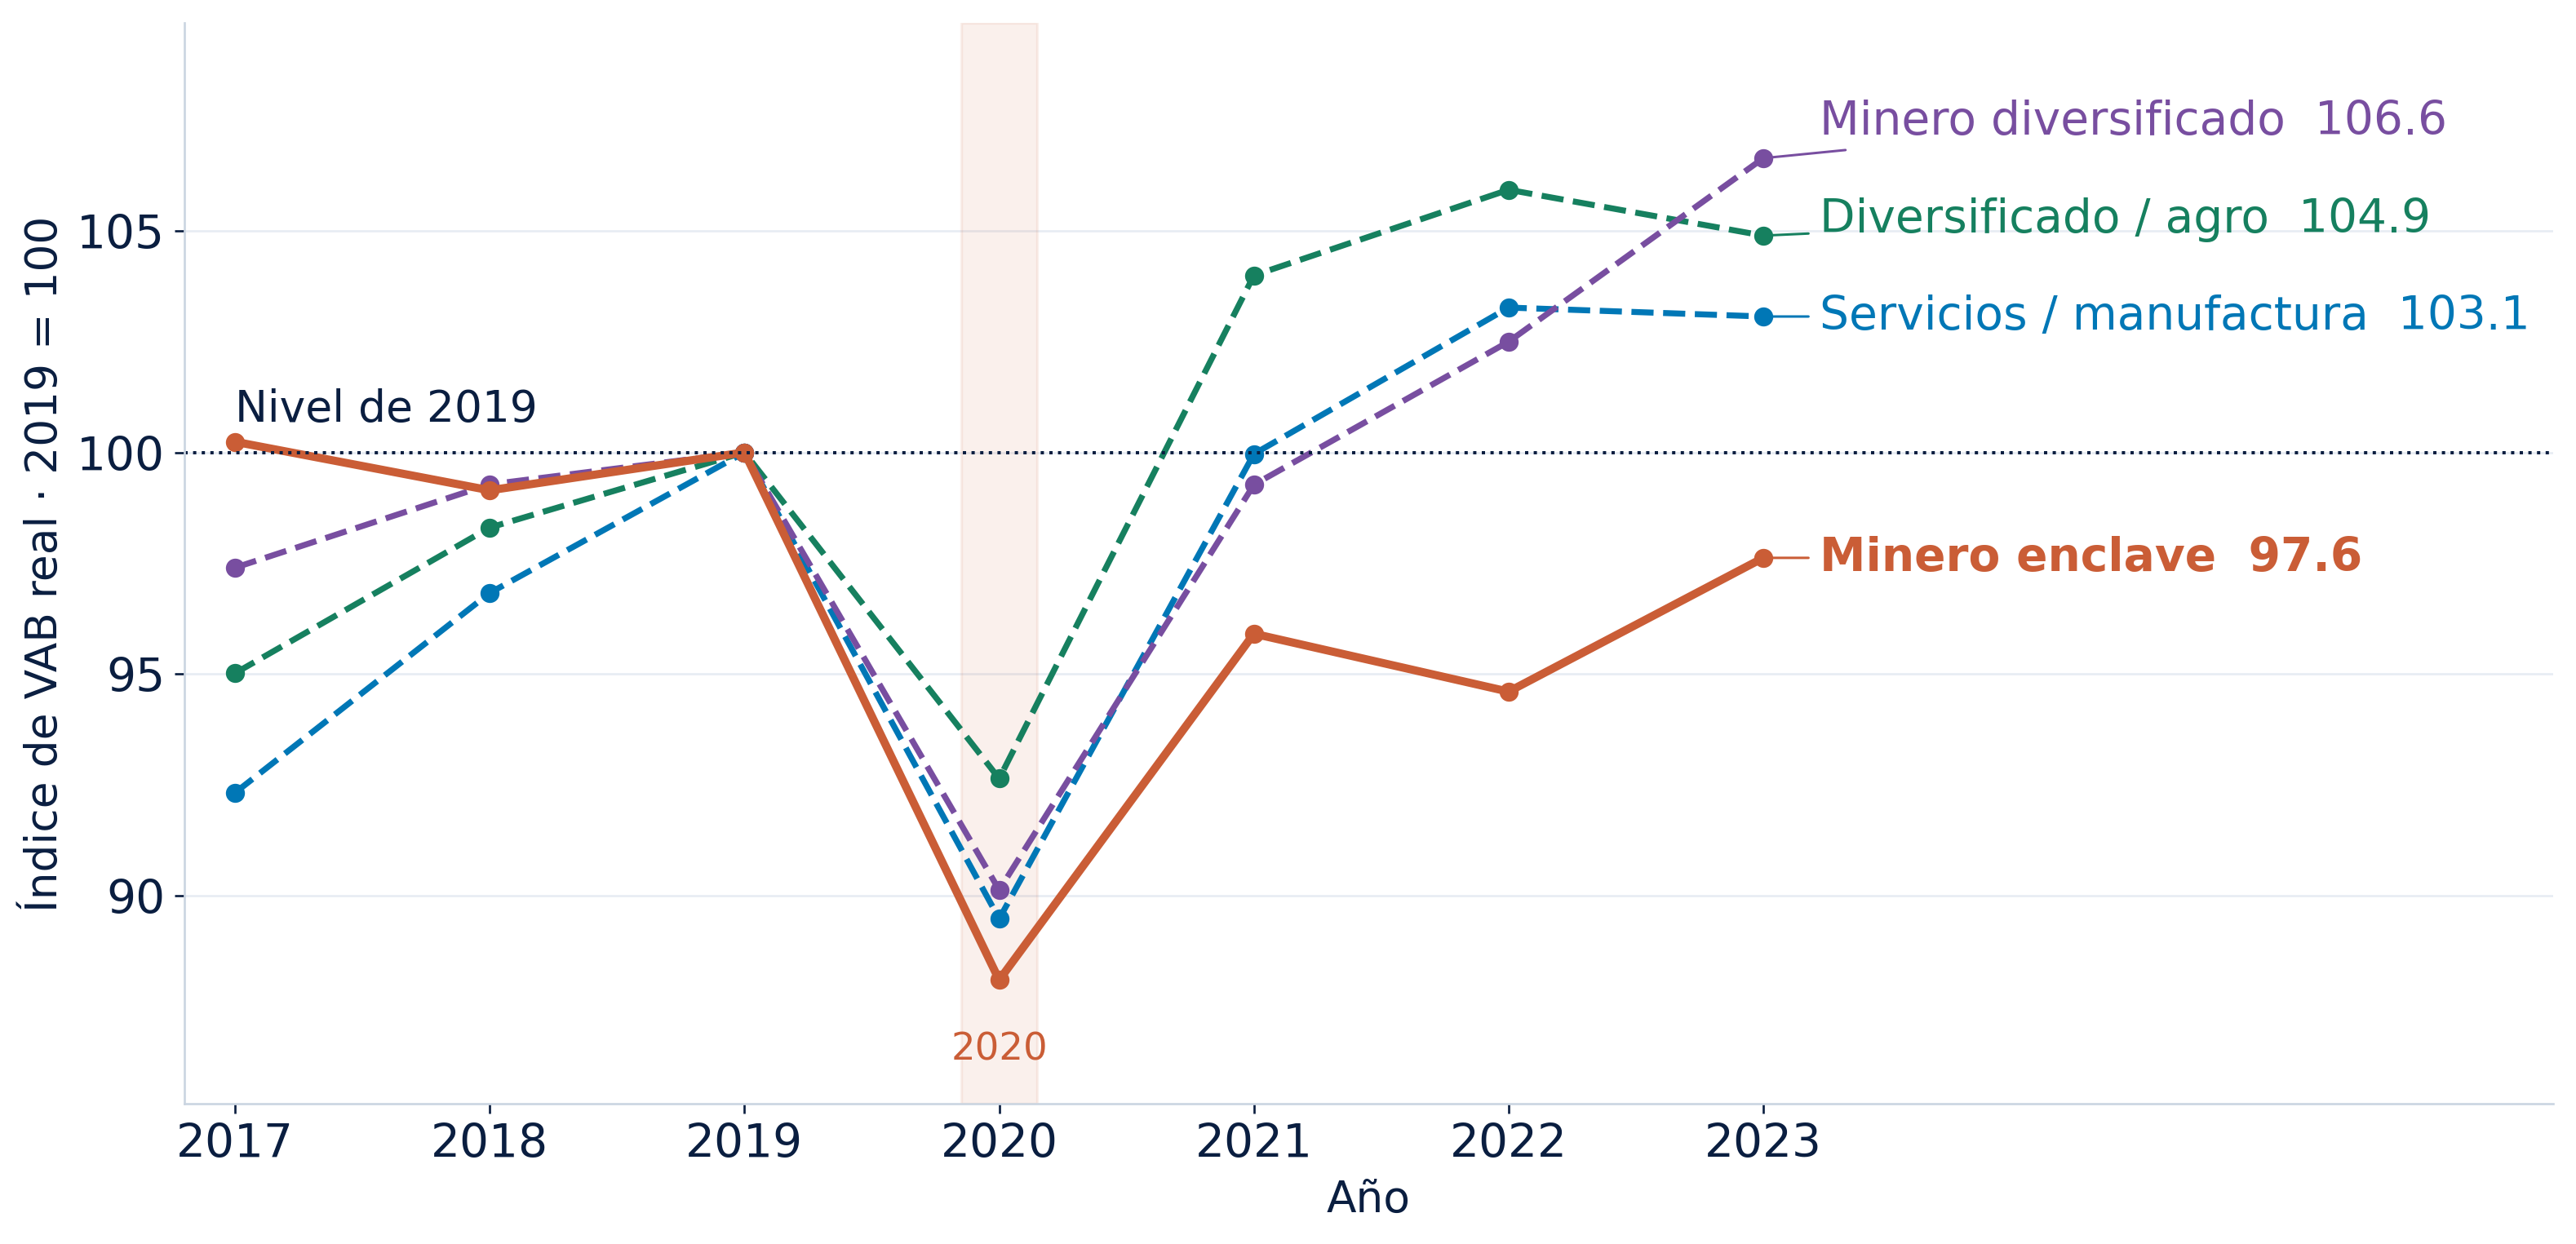

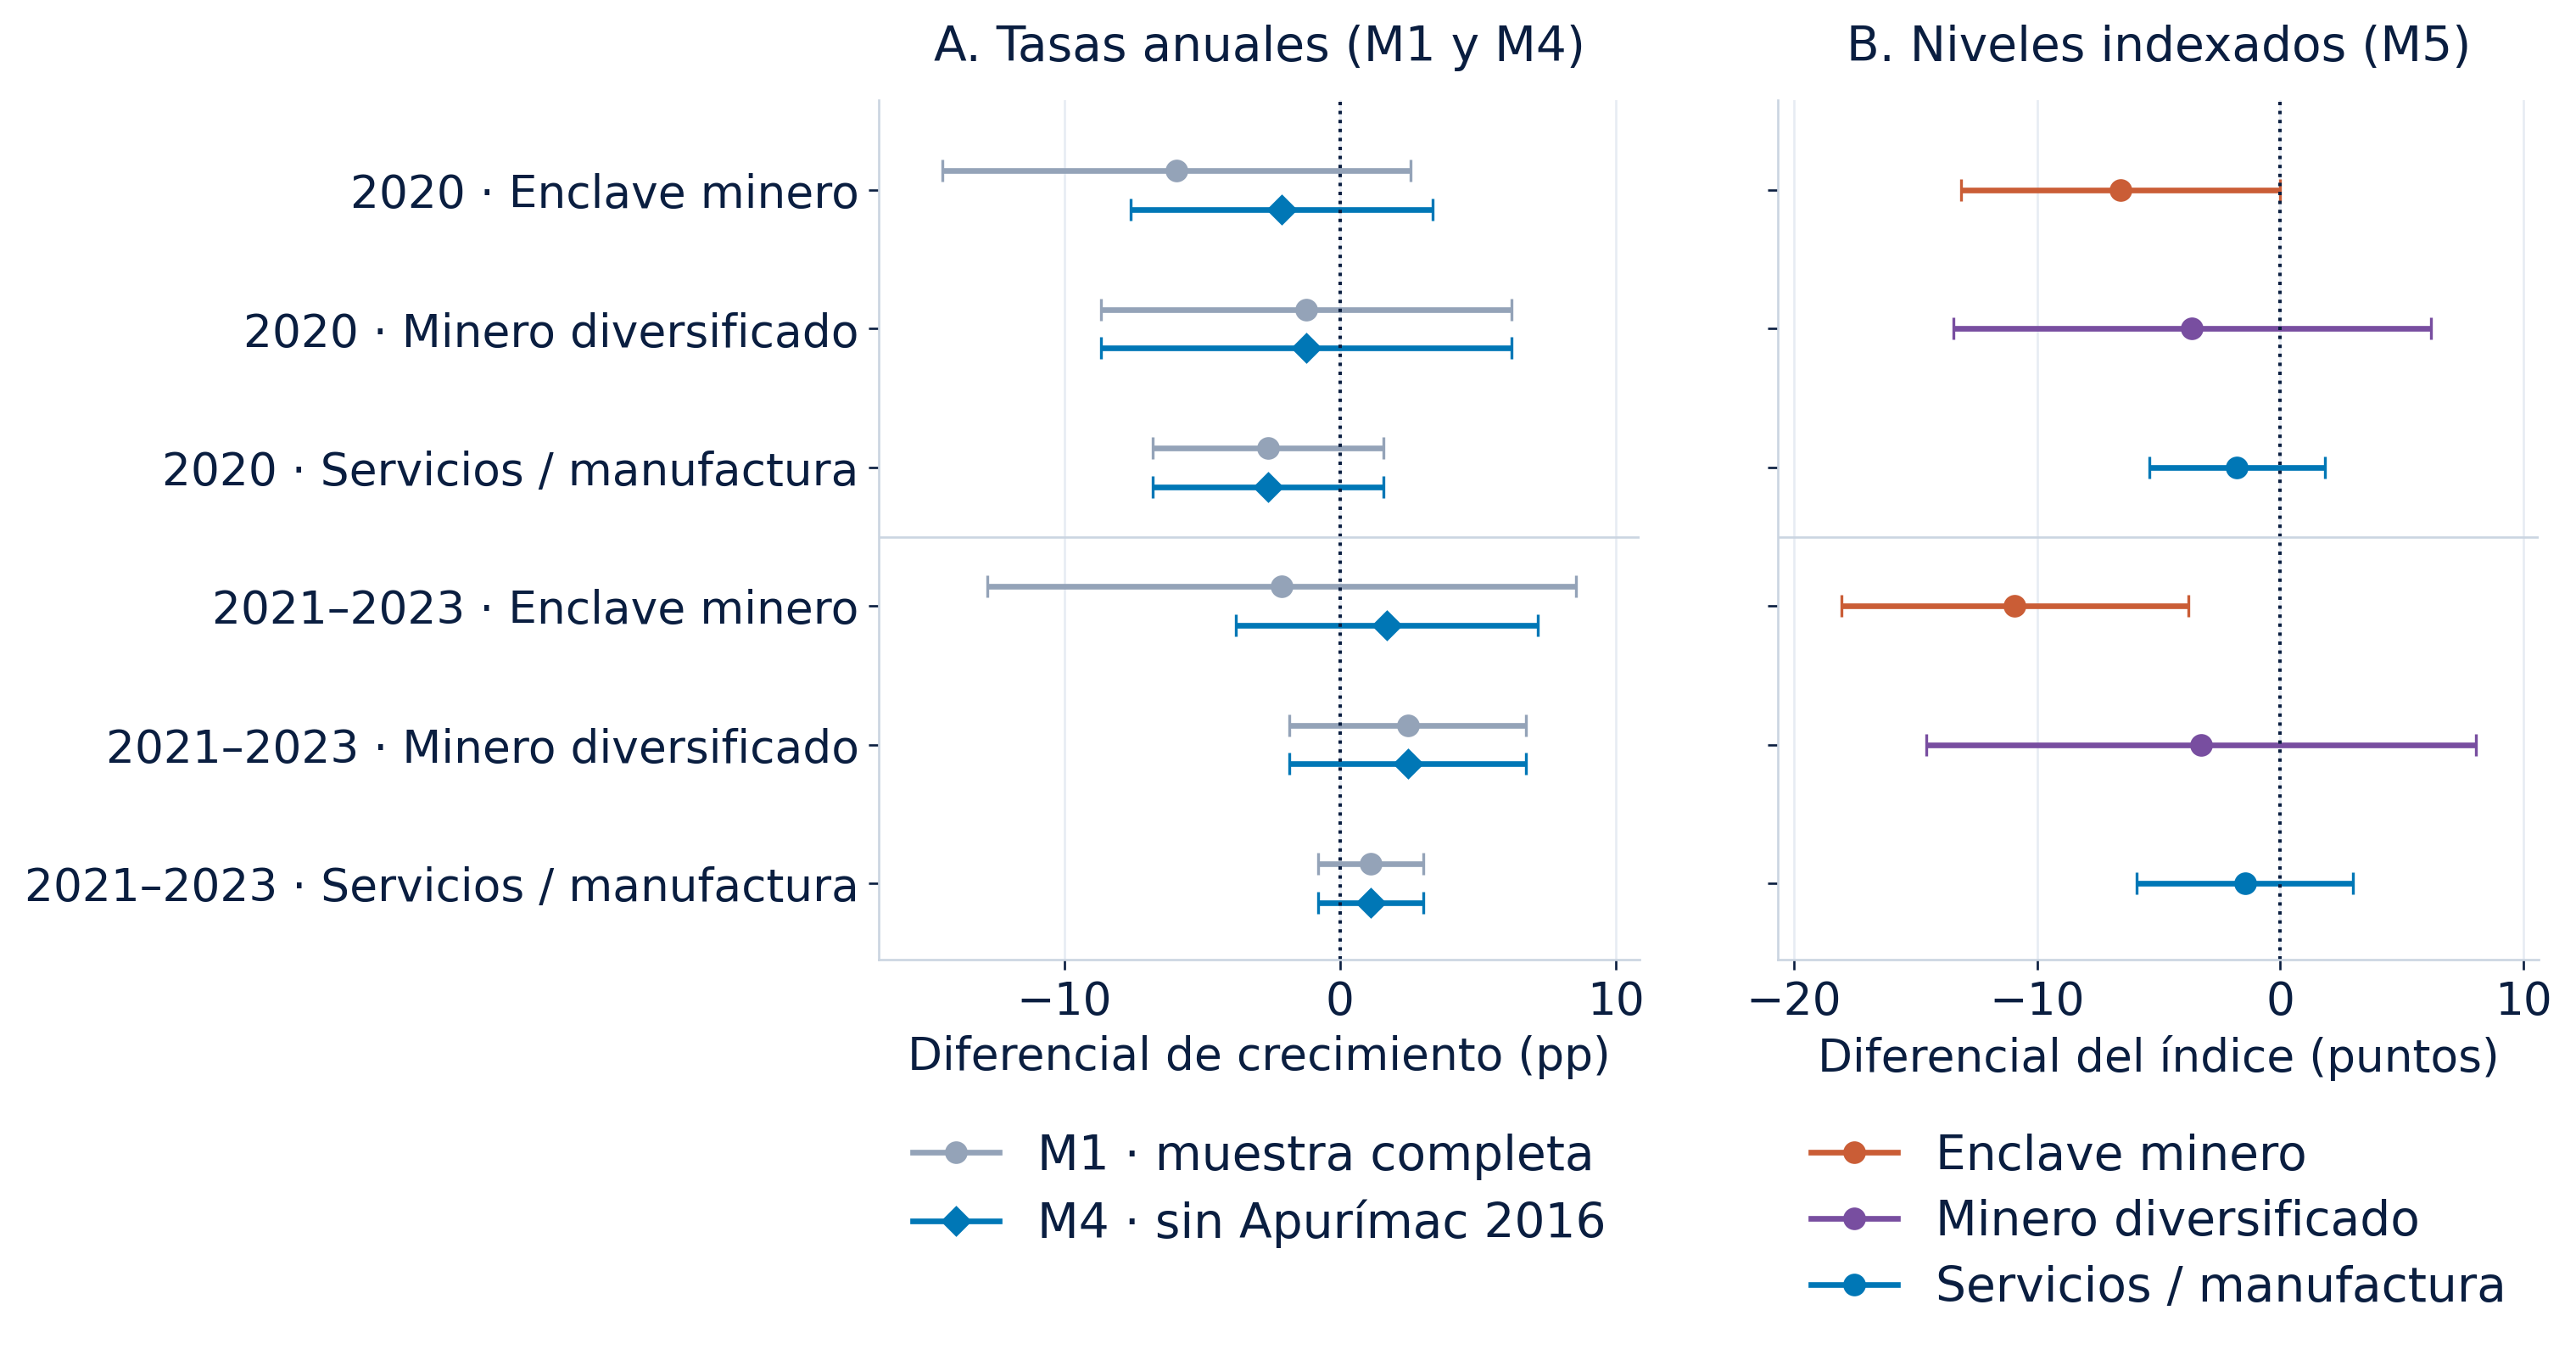

In [3]:
display(Image(filename=str(ROOT / "figures" / "fig4_volatilidad_estructural.png"), width=1000))
display(Image(filename=str(ROOT / "figures" / "fig5_trayectoria_vab_indexado.png"), width=1000))
display(Image(filename=str(ROOT / "figures" / "fig6_forest_plot_modelos.png"), width=1000))